## CNN + LSTM 

### 1. Imports & configuration

In [1]:
import os, json, pickle, joblib, gc, time
import numpy as np
import pandas as pd
from itertools import combinations
from collections import Counter
from concurrent.futures import ProcessPoolExecutor, wait, FIRST_COMPLETED, as_completed
from PIL import Image

from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import RFE
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    precision_score, recall_score, f1_score, accuracy_score,
    roc_auc_score, confusion_matrix
)
from scipy.stats import skew, kurtosis

import matplotlib.pyplot as plt
import seaborn as sns

try:
    from tqdm.auto import tqdm
except ImportError:
    def tqdm(it, **kwargs):
        return it

import warnings
warnings.filterwarnings("ignore")


In [ ]:
CKPT_DIR = '/kaggle/working' if os.path.isdir('/kaggle/working') else '.'

RFE_CKPT  = os.path.join(CKPT_DIR, 'ckpt_rfe_selection.pkl')

SEED    = 42
N_FOLDS = 5
import random
random.seed(SEED)
np.random.seed(SEED)
os.environ['PYTHONHASHSEED'] = str(SEED)
os.environ['CUBLAS_WORKSPACE_CONFIG'] = ':4096:8'   

print(f"CKPT_DIR = {CKPT_DIR} | SEED = {SEED} | N_FOLDS = {N_FOLDS}")

CKPT_DIR = /kaggle/working | SEED = 42 | N_FOLDS = 5


### 2. Dataset DREAM

In [3]:
KAGGLE_INPUT = '/kaggle/input'

def find_dream_root(base):
    for root, dirs, files in os.walk(base):
        json_subdirs = [
            d for d in dirs
            if any(f.endswith('.json')
                   for f in os.listdir(os.path.join(root, d))
                   if os.path.isfile(os.path.join(root, d, f)))
        ]
        if json_subdirs:
            return root
    return None

if os.path.isdir(KAGGLE_INPUT):
    print("Environment detected : Kaggle")
    dream_root = find_dream_root(KAGGLE_INPUT)
    if dream_root is None:
        raise RuntimeError(
            "DREAM dataset not found in /kaggle/input/\n"
            "Verifie que le dataset est bien ajoute au notebook via 'Add Data'."
        )
    extract_path = dream_root
    print(f"Dataset DREAM trouve dans : {extract_path}")
else:
    print("Environment detected : Colab / local")
    from google.colab import drive
    drive.mount('/content/drive')
    dream_path   = '/content/drive/MyDrive/Master_TSA/Datasets/Dream dataset/snd1156-1-1.zip'
    extract_path = '/content/DREAM'
    os.makedirs(extract_path, exist_ok=True)
    import zipfile
    with zipfile.ZipFile(dream_path, 'r') as z:
        z.extractall(extract_path)
    print("Complete extraction in :", extract_path)


Environment detected : Kaggle
Dataset DREAM trouve dans : /kaggle/input/datasets/rimbenjaballah26/dream-dataset


In [4]:
def safe_first(obj):
    if isinstance(obj, list):
        return obj[0] if obj else {}
    return obj if obj is not None else {}

def assign_label(module, comm, inter):
    try:
        module = int(module)
    except (TypeError, ValueError):
        module = 1
    total = (comm or 0) + (inter or 0)
    cutoffs = {1: (7, 12), 2: (8, 12), 3: (7, 10)}
    asd_cut, aut_cut = cutoffs.get(module, (7, 12))
    if total >= aut_cut:
        return 'Autistic Disorder'
    elif total >= asd_cut:
        return 'ASD (AS, PDD)'
    return None

def to_float_array(lst):
    if not lst:
        return np.empty(0, dtype=float)
    return pd.to_numeric(pd.Series(lst), errors='coerce').to_numpy(dtype=float)

def build_xyz_array(d, keys):
    cols = [to_float_array(d.get(k, [])) for k in keys]
    n = max((len(c) for c in cols), default=0)
    if n == 0:
        return None
    out = np.full((n, len(keys)), np.nan)
    for i, c in enumerate(cols):
        out[:len(c), i] = c
    return out

all_json_files = []
for user_dir in sorted(os.listdir(extract_path)):
    user_path = os.path.join(extract_path, user_dir)
    if not os.path.isdir(user_path):
        continue
    for fname in sorted(os.listdir(user_path)):
        if fname.endswith(".json"):
            all_json_files.append(os.path.join(user_path, fname))

print(f"Fichiers JSON detectes : {len(all_json_files)}")


Fichiers JSON detectes : 3121


### 3. Split train/test 

In [ ]:
if os.path.exists(RFE_CKPT):
    print(f"Checkpoint trouve : {RFE_CKPT} -> chargement (pas de recalcul).")
    with open(RFE_CKPT, 'rb') as f:
        _ck = pickle.load(f)
    le               = _ck['le']
    train_pids       = _ck['train_pids']
    test_pids_unique = _ck['test_pids_unique']

else:
    print("Aucun checkpoint RFE trouve -> lancement de la Partie A (extraction + split + RFE).")
    print("Cette etape peut prendre du temps la premiere fois (elle lit tous les JSON).")

    SEGMENT_SIZE = 25
    JOINTS = ['Head', 'ShoulderCenter', 'ShoulderLeft', 'ShoulderRight',
              'ElbowLeft', 'ElbowRight', 'WristLeft', 'WristRight',
              'HandLeft', 'HandRight']
    JOINT_MAP_RAW = {
        'head':           'Head',
        'sholder_center': 'ShoulderCenter',
        'sholder_left':   'ShoulderLeft',
        'sholder_right':  'ShoulderRight',
        'elbow_left':     'ElbowLeft',
        'elbow_right':    'ElbowRight',
        'wrist_left':     'WristLeft',
        'wrist_right':    'WristRight',
        'hand_left':      'HandLeft',
        'hand_right':     'HandRight',
    }
    ANGLE_TRIPLETS = [
        ('Head',          'ShoulderCenter', 'ShoulderLeft'),
        ('Head',          'ShoulderCenter', 'ShoulderRight'),
        ('ShoulderLeft',  'ShoulderCenter', 'ShoulderRight'),
        ('ShoulderCenter','ShoulderLeft',   'ElbowLeft'),
        ('ShoulderCenter','ShoulderRight',  'ElbowRight'),
        ('ShoulderLeft',  'ElbowLeft',      'WristLeft'),
        ('ShoulderRight', 'ElbowRight',     'WristRight'),
        ('ElbowLeft',     'WristLeft',      'HandLeft'),
        ('ElbowRight',    'WristRight',     'HandRight'),
    ]

    N_WORKERS = max(1, min((os.cpu_count() or 2) - 1, 8))
    MAX_IN_FLIGHT = N_WORKERS * 4
    CHECKPOINT_EVERY = 200
    CHECKPOINT_SECONDS = 180
    CHECKPOINT_PKL = os.path.join(CKPT_DIR, 'feat_checkpoint.pkl')

    def euclidean_dist(A, B):
        return float(np.sqrt(np.sum((A - B) ** 2)))

    def angle_between(P1, P2, P3):
        v1 = P1 - P2; v2 = P3 - P2
        cos_a = np.dot(v1, v2) / (np.linalg.norm(v1) * np.linalg.norm(v2) + 1e-9)
        return float(np.degrees(np.arccos(np.clip(cos_a, -1, 1))))

    def extract_features_arrays(seg_arrays, gaze_arrays, normative):
        feats = {}
        means = {j: seg_arrays[j].mean(axis=0) for j in JOINTS}
        for jA, jB in combinations(JOINTS, 2):
            feats[f'{jA}_{jB}_dist'] = euclidean_dist(means[jA], means[jB])
        for P1n, P2n, P3n in ANGLE_TRIPLETS:
            feats[f'{P1n}_{P2n}_{P3n}_angle'] = angle_between(means[P1n], means[P2n], means[P3n])
        vectors = {}
        for name in ['head', 'eye']:
            G_arr = gaze_arrays.get(name)
            if G_arr is not None and G_arr.shape[0] > 0:
                G = G_arr.mean(axis=0)
                mag = np.linalg.norm(G) + 1e-9
                feats[f'{name}_alpha'] = float(np.degrees(np.arccos(np.clip(G[0]/mag, -1, 1))))
                feats[f'{name}_beta']  = float(np.degrees(np.arccos(np.clip(G[1]/mag, -1, 1))))
                feats[f'{name}_gamma'] = float(np.degrees(np.arccos(np.clip(G[2]/mag, -1, 1))))
                vectors[name] = G
            else:
                feats[f'{name}_alpha'] = feats[f'{name}_beta'] = feats[f'{name}_gamma'] = np.nan
        if 'head' in vectors and 'eye' in vectors:
            H, E = vectors['head'], vectors['eye']
            H_mag = np.linalg.norm(H) + 1e-9
            E_mag = np.linalg.norm(E) + 1e-9
            cos_t = np.dot(E, H) / (E_mag * H_mag)
            theta = np.arccos(np.clip(cos_t, -1, 1))
            feats['gaze_angle_EH'] = float(np.degrees(theta))
            feats['gaze_zone_phi'] = float(np.degrees(np.arctan2(H_mag*np.sin(theta), E_mag+H_mag*np.cos(theta))))
        else:
            feats['gaze_angle_EH'] = feats['gaze_zone_phi'] = np.nan
        for j in JOINTS:
            for ax_i, ax in enumerate(['x','y','z']):
                col = f'skeleton_{j.lower()}_{ax}'
                feats[f'{col}_std'] = float(seg_arrays[j][:, ax_i].std())
        for name in ['head', 'eye']:
            G_arr = gaze_arrays.get(name)
            for ax_i, ax in enumerate(['rx','ry','rz']):
                col = f'{name}_gaze_{ax}'
                feats[f'{col}_std'] = float(G_arr[:, ax_i].std()) if G_arr is not None else np.nan
        feats.update(normative)
        return feats

    def process_json_file(fpath):
        with open(fpath) as f:
            data = json.load(f)
        p         = safe_first(data.get('participant', {}))
        ados      = data.get('ados', {})
        ados_data = ados.get('preTest', {}) if isinstance(ados, dict) else {}
        t         = data.get('task', {}) if isinstance(data.get('task'), dict) else {}
        comm   = ados_data.get('communication')
        inter  = ados_data.get('interaction')
        module = ados_data.get('module')
        label  = assign_label(module, comm, inter)
        if label is None:
            return []
        pid        = p.get('id', p.get('child_id'))
        age_months = p.get('ageInMonths', p.get('age_months'))
        gender_raw = str(p.get('gender', 'unknown'))
        cond_raw   = data.get('condition', p.get('condition', 'SHT'))
        difficulty_raw = t.get('difficultyLevel', t.get('task_ability', 0))
        ability_raw= str(t.get('ability', t.get('task_ability', 'unknown')))
        ados_score = (comm or 0) + (inter or 0)
        skel = data.get('skeleton', {})
        hg   = data.get('head_gaze', {})
        eg   = data.get('eye_gaze',  {})
        joint_series = {}
        for raw_key, canon in JOINT_MAP_RAW.items():
            joint = skel.get(raw_key, {})
            joint_series[canon] = build_xyz_array(joint, ('x', 'y', 'z')) if isinstance(joint, dict) else None
        gaze_series = {
            'head': build_xyz_array(hg, ('rx', 'ry', 'rz')),
            'eye':  build_xyz_array(eg, ('rx', 'ry', 'rz')),
        }
        lengths = [a.shape[0] for a in joint_series.values() if a is not None]
        lengths += [a.shape[0] for a in gaze_series.values() if a is not None]
        if not lengths:
            return []
        n_frames = max(lengths)
        n_segs = n_frames // SEGMENT_SIZE
        if n_segs == 0:
            return []
        feats_list = []
        for i in range(n_segs):
            s, e = i * SEGMENT_SIZE, (i + 1) * SEGMENT_SIZE
            seg_arrays = {}
            for j in JOINTS:
                arr = joint_series[j]
                if arr is not None and s < arr.shape[0]:
                    seg_arrays[j] = arr[s:min(e, arr.shape[0])]
                    if len(seg_arrays[j]) < SEGMENT_SIZE:
                        pad = np.full((SEGMENT_SIZE - len(seg_arrays[j]), 3), np.nan)
                        seg_arrays[j] = np.vstack([seg_arrays[j], pad])
                else:
                    seg_arrays[j] = np.full((SEGMENT_SIZE, 3), np.nan)
            seg_gaze = {}
            for name, arr in gaze_series.items():
                if arr is not None and s < arr.shape[0]:
                    sliced = arr[s:min(e, arr.shape[0])]
                    if len(sliced) < SEGMENT_SIZE:
                        pad = np.full((SEGMENT_SIZE - len(sliced), 3), np.nan)
                        sliced = np.vstack([sliced, pad])
                    seg_gaze[name] = sliced
                else:
                    seg_gaze[name] = None
            normative = {
                'participant_ageInMonths': age_months,
                'age_group':    0,
                'gender':       gender_raw,
                'task_ability': ability_raw,
                'task_difficulty': difficulty_raw,
            }
            feats = extract_features_arrays(seg_arrays, seg_gaze, normative)
            feats['participant_id'] = pid
            feats['label']          = label
            feats['ados_score']     = ados_score
            feats['age_months']     = age_months
            feats['condition']      = cond_raw
            feats_list.append(feats)
        return feats_list

    processed_set = set()
    all_feats = []
    if os.path.exists(CHECKPOINT_PKL):
        with open(CHECKPOINT_PKL, 'rb') as f:
            ck = pickle.load(f)
        processed_set = ck.get('processed', set())
        all_feats     = ck.get('feats', [])
        print(f"Checkpoint extraction trouve -> {len(processed_set)} fichiers deja traites.")

    remaining_files = [f for f in all_json_files if f not in processed_set]
    print(f"Fichiers restants a traiter : {len(remaining_files)}")

    def save_checkpoint():
        with open(CHECKPOINT_PKL, 'wb') as f:
            pickle.dump({'feats': all_feats, 'processed': processed_set}, f)

    n_done = len(processed_set)
    t0 = time.time()

    if remaining_files:
        file_iter = iter(remaining_files)
        last_ckpt_time = time.time()
        with ProcessPoolExecutor(max_workers=N_WORKERS) as ex:
            futures = {}
            for _ in range(min(MAX_IN_FLIGHT, len(remaining_files))):
                fp = next(file_iter)
                futures[ex.submit(process_json_file, fp)] = fp
            pbar = tqdm(total=len(remaining_files), desc="Extraction features")
            while futures:
                done, _ = wait(futures, return_when=FIRST_COMPLETED)
                for fut in done:
                    fp = futures.pop(fut)
                    try:
                        feats = fut.result()
                        all_feats.extend(feats)
                    except Exception as e:
                        pass
                    processed_set.add(fp)
                    n_done += 1
                    pbar.update(1)
                    try:
                        nf = next(file_iter)
                        futures[ex.submit(process_json_file, nf)] = nf
                    except StopIteration:
                        pass
                    now = time.time()
                    if n_done % CHECKPOINT_EVERY == 0 or (now - last_ckpt_time) > CHECKPOINT_SECONDS:
                        save_checkpoint()
                        last_ckpt_time = now
            pbar.close()
        save_checkpoint()

    feat_df = pd.DataFrame(all_feats)
    gc.collect()
    feat_df['gender']       = LabelEncoder().fit_transform(feat_df['gender'].astype(str))
    feat_df['task_ability'] = LabelEncoder().fit_transform(feat_df['task_ability'].astype(str))
    feat_df['age_group']    = pd.cut(feat_df['age_months'], bins=5, labels=[0,1,2,3,4]).astype(int)
    feat_df['participant_ageInMonths'] = feat_df['age_months']
    print(f"Segments totaux : {len(feat_df)} | Participants : {feat_df['participant_id'].nunique()}")

    EXCLUDE = {'participant_id', 'label', 'ados_score', 'age_months', 'condition'}
    FEATURE_COLS = [c for c in feat_df.columns if c not in EXCLUDE]
    X_raw = feat_df[FEATURE_COLS].copy()
    y_clf_raw = feat_df['label']
    y_reg_raw = feat_df['ados_score']

    X_raw = X_raw.dropna(axis=1, how='all')
    FEATURE_COLS = list(X_raw.columns)

    nan_rate_by_pid = (
        feat_df.assign(**{c: X_raw[c] for c in FEATURE_COLS})
               .groupby('participant_id')[FEATURE_COLS]
               .apply(lambda g: g.isna().mean().mean())
    )
    nan_rate_sorted = nan_rate_by_pid.sort_values(ascending=False)
    N_TO_EXCLUDE = 7
    excluded_pids = nan_rate_sorted.head(N_TO_EXCLUDE).index.tolist()
    print(f"Participants exclus (trop de NaN) : {excluded_pids}")

    keep_mask = ~feat_df['participant_id'].isin(excluded_pids).values
    feat_df_clean = feat_df.loc[keep_mask].reset_index(drop=True)
    X_raw          = X_raw.loc[keep_mask].reset_index(drop=True)
    y_clf_raw      = y_clf_raw.loc[keep_mask].reset_index(drop=True)
    y_reg_raw      = y_reg_raw.loc[keep_mask].reset_index(drop=True)

    participant_label = feat_df_clean.groupby('participant_id')['label'].agg(
        lambda s: s.value_counts().idxmax()
    )
    train_ids, test_ids = train_test_split(
        participant_label.index.to_numpy(),
        test_size=8,
        stratify=participant_label.values,
        random_state=42
    )
    print(f"Train : {len(train_ids)} participants | Test : {len(test_ids)} participants")

    train_mask = feat_df_clean['participant_id'].isin(train_ids).values
    test_mask  = feat_df_clean['participant_id'].isin(test_ids).values

    train_medians = X_raw[train_mask].median(numeric_only=True)
    X_raw = X_raw.fillna(train_medians)

    le = LabelEncoder()
    y_clf = le.fit_transform(y_clf_raw)
    y_reg = y_reg_raw.values

    X_train_raw = X_raw.values[train_mask]
    X_test_raw  = X_raw.values[test_mask]
    y_train_clf = y_clf[train_mask]
    y_test_clf  = y_clf[test_mask]
    y_train_reg = y_reg[train_mask]
    y_test_reg  = y_reg[test_mask]

    train_pids = feat_df_clean['participant_id'].values[train_mask]
    test_pids_unique = sorted(test_ids.tolist())

    rf_base = RandomForestClassifier(n_estimators=50, criterion='entropy', random_state=42, n_jobs=-1)
    rfe = RFE(estimator=rf_base, n_features_to_select=53, step=5)
    rfe.fit(X_train_raw, y_train_clf)

    X_train_sel = rfe.transform(X_train_raw)
    X_test_sel  = rfe.transform(X_test_raw)
    selected_features = [FEATURE_COLS[i] for i, s in enumerate(rfe.support_) if s]

    with open(RFE_CKPT, 'wb') as f:
        pickle.dump({
            'FEATURE_COLS': FEATURE_COLS,
            'X_train_sel': X_train_sel, 'X_test_sel': X_test_sel,
            'y_train_clf': y_train_clf, 'y_test_clf': y_test_clf,
            'y_train_reg': y_train_reg, 'y_test_reg': y_test_reg,
            'le': le, 'selected_features': selected_features,
            'train_pids': train_pids,
            'test_pids_unique': test_pids_unique,
        }, f)
    print(f"Checkpoint RFE sauvegarde -> {RFE_CKPT}")

train_pid_set = set(train_pids.tolist() if hasattr(train_pids, 'tolist') else train_pids)
test_pid_set  = set(test_pids_unique)

print(f"Participants train : {len(train_pid_set)} | Participants test : {len(test_pid_set)}")
print(f"Classes : {le.classes_}")


Aucun checkpoint RFE trouve -> lancement de la Partie A (extraction + split + RFE).
Cette etape peut prendre du temps la premiere fois (elle lit tous les JSON).
Fichiers restants a traiter : 3121


Extraction features:   0%|          | 0/3121 [00:00<?, ?it/s]

Segments totaux : 1012441 | Participants : 61
Participants exclus (trop de NaN) : [31, 14, 15, 32, 44, 50, 30]
Train : 46 participants | Test : 8 participants
Checkpoint RFE sauvegarde -> /kaggle/working/ckpt_rfe_selection.pkl
Participants train : 46 | Participants test : 8
Classes : ['ASD (AS, PDD)' 'Autistic Disorder']


### 5. Viewframes + gaze projection


In [6]:
VIEWFRAMES = {
    'front':  {'center': np.array([0.0, 0.0, 700.0]),
               'width_axis': np.array([1.0, 0.0, 0.0]), 'height_axis': np.array([0.0, 1.0, 0.0]),
               'width': 800.0, 'height': 600.0},
    'left':   {'center': np.array([-450.0, 0.0, 0.0]),
               'width_axis': np.array([0.0, 0.0, 1.0]), 'height_axis': np.array([0.0, 1.0, 0.0]),
               'width': 600.0, 'height': 600.0},
    'right':  {'center': np.array([450.0, 0.0, 0.0]),
               'width_axis': np.array([0.0, 0.0, 1.0]), 'height_axis': np.array([0.0, 1.0, 0.0]),
               'width': 600.0, 'height': 600.0},
    'top':    {'center': np.array([0.0, 450.0, 0.0]),
               'width_axis': np.array([1.0, 0.0, 0.0]), 'height_axis': np.array([0.0, 0.0, 1.0]),
               'width': 800.0, 'height': 600.0},
    'bottom': {'center': np.array([0.0, -300.0, 0.0]),
               'width_axis': np.array([1.0, 0.0, 0.0]), 'height_axis': np.array([0.0, 0.0, 1.0]),
               'width': 800.0, 'height': 600.0},
}

def ray_plane_intersection(Pv, D, vf):
    width_axis, height_axis = vf['width_axis'], vf['height_axis']
    width, height, center = vf['width'], vf['height'], vf['center']
    corner = center - (width / 2.0) * width_axis - (height / 2.0) * height_axis
    E1 = width_axis * width
    E2 = height_axis * height
    N = np.cross(E1, E2)
    N = N / np.linalg.norm(N)
    denom = D @ N
    if abs(denom) < 1e-9:
        return None
    t = ((corner - Pv) @ N) / denom
    if t <= 0:
        return None
    Pi = Pv + t * D
    rel = Pi - corner
    u_proj = rel @ width_axis
    v_proj = rel @ height_axis
    if 0.0 <= u_proj <= width and 0.0 <= v_proj <= height:
        return (u_proj - width / 2.0, v_proj - height / 2.0)
    return None

def assign_viewframe(Pv, D):
    for name in ['front', 'left', 'right', 'top', 'bottom']:
        res = ray_plane_intersection(Pv, D, VIEWFRAMES[name])
        if res is not None:
            return name, res[0], res[1]
    return None, None, None


### 6. Evaluation 


In [7]:
def evaluate_at_participant_level(probs, y_true_seg, pids_seg, test_pid_set, label_names):
    prob_by_pid, true_by_pid = {}, {}
    for pid in test_pid_set:
        m = np.array(pids_seg) == pid
        if m.sum() == 0:
            continue
        prob_by_pid[pid] = probs[m].mean(axis=0)
        true_by_pid[pid] = Counter(y_true_seg[m]).most_common(1)[0][0]

    pids_sorted = sorted(prob_by_pid.keys())
    y_true_p = [true_by_pid[pid] for pid in pids_sorted]
    y_pred_p = [int(np.argmax(prob_by_pid[pid])) for pid in pids_sorted]

    metrics = {
        'precision': precision_score(y_true_p, y_pred_p, average="macro", zero_division=0) * 100,
        'recall':    recall_score(y_true_p, y_pred_p, average="macro", zero_division=0) * 100,
        'f1':        f1_score(y_true_p, y_pred_p, average="macro", zero_division=0) * 100,
        'accuracy':  accuracy_score(y_true_p, y_pred_p) * 100,
        'n_participants': len(pids_sorted),
    }
    cm = confusion_matrix(y_true_p, y_pred_p)
    return metrics, cm, y_true_p, y_pred_p


def get_participant_level_probs(probs, pids_seg, test_pid_set):
    prob_by_pid = {}
    for pid in test_pid_set:
        m = np.array(pids_seg) == pid
        if m.sum() == 0:
            continue
        prob_by_pid[pid] = probs[m].mean(axis=0)
    pids_sorted = sorted(prob_by_pid.keys())
    y_prob_p = np.stack([prob_by_pid[pid] for pid in pids_sorted])
    return y_prob_p, pids_sorted


### 7. Saliency maps

In [8]:
IMG_SIZE = 224

def compute_bandwidth(pts):
    n = len(pts)
    mean = pts.mean(axis=0)
    d = np.linalg.norm(pts - mean, axis=1)
    SD = np.sqrt(np.mean(d ** 2))
    Dm = np.median(d)
    SB = 0.9 * min(SD, np.sqrt(1.0 / np.log(2)) * Dm) * (n ** (-0.2))
    return max(SB, 1e-3)

def gaussian_kernel_2d(x):
    return (1.0 / (2.0 * np.pi)) * np.exp(-0.5 * np.sum(x ** 2, axis=-1))

def render_saliency_panel(points, half_u, half_v, grid_size=128):
    if len(points) < 5:
        return None
    pts = np.array(points)
    h = compute_bandwidth(pts)
    n = len(pts)
    uu, vv = np.meshgrid(
        np.linspace(-half_u, half_u, grid_size),
        np.linspace(-half_v, half_v, grid_size)
    )
    grid = np.stack([uu.ravel(), vv.ravel()], axis=-1)
    diffs = (grid[:, None, :] - pts[None, :, :]) / h
    kernel_vals = gaussian_kernel_2d(diffs)
    density = kernel_vals.sum(axis=1) / (n * h ** 2)
    density = density.reshape(grid_size, grid_size)
    density = (density - density.min()) / (density.max() - density.min() + 1e-9)
    return density

def build_multichannel_saliency_image(points_by_vf, img_size=IMG_SIZE, grid_size=128):
    def panel_or_zeros(name):
        p = render_saliency_panel(points_by_vf[name],
                                   VIEWFRAMES[name]['width'] / 2.0,
                                   VIEWFRAMES[name]['height'] / 2.0,
                                   grid_size=grid_size)
        return p if p is not None else np.zeros((grid_size, grid_size))

    front = panel_or_zeros('front')
    left, right = panel_or_zeros('left'), panel_or_zeros('right')
    top, bottom = panel_or_zeros('top'), panel_or_zeros('bottom')

    R = front
    G = (left + right) / 2.0
    B = (top + bottom) / 2.0

    rgb = np.stack([R, G, B], axis=-1)
    rgb_img = (rgb * 255).astype(np.uint8)
    rgb_img = np.array(Image.fromarray(rgb_img).resize((img_size, img_size)))
    return rgb_img


In [9]:
N_CHUNKS_VGG = 4

def process_json_file_gaze_chunks_vgg(fpath, n_chunks=N_CHUNKS_VGG, img_size=IMG_SIZE):
    with open(fpath) as f:
        data = json.load(f)

    p = safe_first(data.get('participant', {}))
    ados = data.get('ados', {})
    ados_data = ados.get('preTest', {}) if isinstance(ados, dict) else {}
    comm, inter, module = ados_data.get('communication'), ados_data.get('interaction'), ados_data.get('module')
    label = assign_label(module, comm, inter)
    if label is None:
        return []

    pid = p.get('id', p.get('child_id'))
    skel = data.get('skeleton', {})
    eg = data.get('eye_gaze', {})

    head_arr = build_xyz_array(skel.get('head', {}), ('x', 'y', 'z'))
    eye_arr = build_xyz_array(eg, ('rx', 'ry', 'rz'))
    if head_arr is None or eye_arr is None:
        return []

    n = min(len(head_arr), len(eye_arr))
    if n == 0:
        return []
    head_arr, eye_arr = head_arr[:n], eye_arr[:n]
    valid = ~np.isnan(head_arr).any(axis=1) & ~np.isnan(eye_arr).any(axis=1)
    head_v, eye_v = head_arr[valid], eye_arr[valid]
    n_valid = len(head_v)
    if n_valid < 5 * n_chunks:
        return []

    bounds = np.linspace(0, n_valid, n_chunks + 1).astype(int)
    results = []
    for c in range(n_chunks):
        h_c, e_c = head_v[bounds[c]:bounds[c+1]], eye_v[bounds[c]:bounds[c+1]]
        points_by_vf = {name: [] for name in VIEWFRAMES}
        for Pv, D_raw in zip(h_c, e_c):
            norm = np.linalg.norm(D_raw)
            if norm < 1e-9:
                continue
            D = D_raw / norm
            name, u, v = assign_viewframe(Pv, D)
            if name is not None:
                points_by_vf[name].append((u, v))
        img = build_multichannel_saliency_image(points_by_vf, img_size=img_size)
        results.append({'participant_id': pid, 'label': label, 'image': img, 'chunk': c})
    return results

N_WORKERS = max(1, min((os.cpu_count() or 2) - 1, 8))
VGG_CHUNKS_CKPT = os.path.join(CKPT_DIR, 'ckpt_vgg_chunks_v1.pkl')

if os.path.exists(VGG_CHUNKS_CKPT):
    print(f"Checkpoint trouve -> {VGG_CHUNKS_CKPT} : chargement.")
    with open(VGG_CHUNKS_CKPT, 'rb') as f:
        vgg_chunk_records = pickle.load(f)
else:
    vgg_chunk_records = []
    with ProcessPoolExecutor(max_workers=N_WORKERS) as ex:
        futures = {ex.submit(process_json_file_gaze_chunks_vgg, fp): fp for fp in all_json_files}
        for fut in tqdm(as_completed(futures), total=len(futures), desc="Chunks saliency"):
            vgg_chunk_records.extend(fut.result())
    with open(VGG_CHUNKS_CKPT, 'wb') as f:
        pickle.dump(vgg_chunk_records, f)
    print(f"Checkpoint sauvegarde -> {VGG_CHUNKS_CKPT}")

print(f"Total images generees : {len(vgg_chunk_records)}")

sal_imgs   = np.stack([r['image'] for r in vgg_chunk_records])
sal_labels = np.array([r['label'] for r in vgg_chunk_records])
sal_pids   = np.array([r['participant_id'] for r in vgg_chunk_records])

y_sal_enc = le.transform(sal_labels)
idx_train = [i for i, pid in enumerate(sal_pids) if pid in train_pid_set]
idx_test  = [i for i, pid in enumerate(sal_pids) if pid in test_pid_set]

y_sal_train = y_sal_enc[idx_train]
y_sal_test  = y_sal_enc[idx_test]

print(f"Images train : {len(idx_train)} | Images test : {len(idx_test)}")


Chunks saliency:   0%|          | 0/3121 [00:00<?, ?it/s]

Checkpoint sauvegarde -> /kaggle/working/ckpt_vgg_chunks_v1.pkl
Total images generees : 12148
Images train : 9288 | Images test : 1860


### 8. Sequences for CNN + LSTM

In [10]:
T = N_CHUNKS_VGG
assert len(vgg_chunk_records) % T == 0, "Nombre d'images non multiple de N_CHUNKS_VGG"

chunk_ids  = np.array([r['chunk'] for r in vgg_chunk_records]).reshape(-1, T)
pid_blocks = sal_pids.reshape(-1, T)
lab_blocks = sal_labels.reshape(-1, T)
assert (chunk_ids == np.arange(T)).all(),            "Les chunks ne sont pas groupes par session (0,1,2,3)"
assert (pid_blocks == pid_blocks[:, :1]).all(),      "Plusieurs participants dans une meme sequence"
assert (lab_blocks == lab_blocks[:, :1]).all(),      "Plusieurs labels dans une meme sequence"

seq_pids = pid_blocks[:, 0]
seq_y    = le.transform(lab_blocks[:, 0])
print(f"Sequences (sessions) : {len(seq_pids)} | Participants : {len(set(seq_pids.tolist()))}")

IMG_SIZE_CNN = 112

def downsample(imgs, size):
    f = imgs.shape[1] // size
    out = np.empty((len(imgs), size, size, 3), dtype=np.uint8)
    for s in range(0, len(imgs), 500):
        b = imgs[s:s + 500].astype(np.float32)
        out[s:s + 500] = b.reshape(len(b), size, f, size, f, 3).mean(axis=(2, 4)).round().astype(np.uint8)
    return out

X_seq = downsample(sal_imgs, IMG_SIZE_CNN).reshape(-1, T, IMG_SIZE_CNN, IMG_SIZE_CNN, 3)
print("X_seq :", X_seq.shape, X_seq.dtype)

Sequences (sessions) : 3037 | Participants : 61
X_seq : (3037, 4, 112, 112, 3) uint8


### 9.  CNN + LSTM (PyTorch)

In [ ]:
import torch, torch.nn as nn, torch.nn.functional as F

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
torch.use_deterministic_algorithms(True, warn_only=True)

# Hyperparametres 
EPOCHS       = 20      
BATCH_SIZE   = 16      
LR           = 1e-3
WEIGHT_DECAY = 1e-4
FEAT_DIM     = 128
LSTM_HIDDEN  = 64
DROPOUT      = 0.3
REG_WEIGHT   = 1.0     # loss totale = loss classification + REG_WEIGHT * loss regression
N_CLASSES    = len(le.classes_)

# tenseur uint8 (N, T, 3, H, W), converti en float a la volee
X_t = torch.from_numpy(X_seq).permute(0, 1, 4, 2, 3).contiguous()
print(f"Device : {DEVICE} | X_t : {tuple(X_t.shape)}")

def set_seed(seed):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

class CNNLSTM(nn.Module):
    """CNN (par image) -> LSTM bidirectionnel (sur la sequence) -> 2 tetes : classification + regression."""
    def __init__(self, n_classes=N_CLASSES, feat_dim=FEAT_DIM, hidden=LSTM_HIDDEN, dropout=DROPOUT):
        super().__init__()
        def block(cin, cout):
            return nn.Sequential(nn.Conv2d(cin, cout, 3, padding=1), nn.BatchNorm2d(cout),
                                 nn.ReLU(inplace=True), nn.MaxPool2d(2))
        self.cnn = nn.Sequential(block(3, 16), block(16, 32), block(32, 64), block(64, feat_dim),
                                 nn.AdaptiveAvgPool2d(1), nn.Flatten())
        self.lstm = nn.LSTM(feat_dim, hidden, batch_first=True, bidirectional=True)
        self.drop = nn.Dropout(dropout)
        self.head_cls = nn.Linear(2 * hidden, n_classes)   # tete classification (logits)
        self.head_reg = nn.Linear(2 * hidden, 1)           # tete regression (valeur dans [0, 1])

    def forward(self, x):                       # x : (B, T, 3, H, W)
        B, Tn = x.shape[:2]
        f = self.cnn(x.flatten(0, 1)).view(B, Tn, -1)    # (B, T, feat_dim)
        o, _ = self.lstm(f)                              # (B, T, 2*hidden)
        o = self.drop(o)
        return self.head_cls(o), torch.sigmoid(self.head_reg(o)).squeeze(-1)   # (B,T,C), (B,T)

def make_batch(idx):
    x = X_t[idx].to(DEVICE).float().div_(255.0)
    return (x - 0.5) / 0.5

@torch.no_grad()
def predict_outputs(model, idx, bs=64):
    model.eval()
    lg, rg = [], []
    for s in range(0, len(idx), bs):
        l, r = model(make_batch(idx[s:s + bs]))
        lg.append(l.cpu()); rg.append(r.cpu())
    return torch.cat(lg), torch.cat(rg)                  # (N, T, n_classes), (N, T)

def multitask_loss(logits, reg, y_seq, w):
    y_chunk = y_seq[:, None].expand(-1, T).reshape(-1)
    l_cls = F.cross_entropy(logits.reshape(-1, N_CLASSES), y_chunk, weight=w)
    l_reg = F.mse_loss(reg.reshape(-1), y_chunk.float())
    return l_cls + REG_WEIGHT * l_reg, l_cls, l_reg

def train_fold(idx_tr, idx_te, seed=SEED):
    set_seed(seed)
    model = CNNLSTM().to(DEVICE)
    y_tr = torch.as_tensor(seq_y[idx_tr], dtype=torch.long)
    y_te = torch.as_tensor(seq_y[idx_te], dtype=torch.long)

    counts = np.bincount(seq_y[idx_tr], minlength=N_CLASSES)
    w = torch.tensor(counts.sum() / (N_CLASSES * np.maximum(counts, 1)), dtype=torch.float32)   # equivalent de class_weight='balanced'
    opt = torch.optim.Adam(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    g = torch.Generator().manual_seed(seed)

    hist = {k: [] for k in ['train_total', 'train_cls', 'train_reg', 'val_total', 'val_cls', 'val_reg']}
    idx_tr_t, idx_te_t = torch.as_tensor(idx_tr), torch.as_tensor(idx_te)
    for ep in range(EPOCHS):
        model.train()
        perm = torch.randperm(len(idx_tr_t), generator=g)
        run = np.zeros(3); n = 0
        for s in range(0, len(perm), BATCH_SIZE):
            b = perm[s:s + BATCH_SIZE]
            logits, reg = model(make_batch(idx_tr_t[b]))
            loss, l_cls, l_reg = multitask_loss(logits, reg, y_tr[b].to(DEVICE), w.to(DEVICE))
            opt.zero_grad(set_to_none=True)
            loss.backward()
            opt.step()
            run += np.array([loss.item(), l_cls.item(), l_reg.item()]) * len(b); n += len(b)
        run /= n
        lg_te, rg_te = predict_outputs(model, idx_te_t)
        v_tot, v_cls, v_reg = [t.item() for t in multitask_loss(lg_te, rg_te, y_te, w)]
        for k, v in zip(hist, [*run, v_tot, v_cls, v_reg]):
            hist[k].append(float(v))
        print(f"   epoch {ep+1:02d}/{EPOCHS} | train total {run[0]:.4f} (cls {run[1]:.4f}, reg {run[2]:.4f}) "
              f"| held-out total {v_tot:.4f}")

    lg_te, rg_te = predict_outputs(model, idx_te_t)
    probs = torch.softmax(lg_te, dim=-1).reshape(-1, N_CLASSES).numpy()   # (N_te*T, n_classes)
    reg_out = rg_te.reshape(-1).numpy()                                    # (N_te*T,)
    del model; gc.collect()
    if DEVICE.type == 'cuda':
        torch.cuda.empty_cache()
    return probs, reg_out, hist

Device : cuda | X_t : (3037, 4, 3, 112, 112)


### 10. CNN + LSTM multi-task 


In [ ]:
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

#  Ensemble de tous les participants (train + test du split initial) 
all_pid_set = train_pid_set | test_pid_set
idx_all = np.array([i for i, pid in enumerate(sal_pids) if pid in all_pid_set])   # niveau chunk
pids_all, y_all = sal_pids[idx_all], y_sal_enc[idx_all]

part_ids = np.array(sorted(all_pid_set))
part_lab = np.array([Counter(y_all[pids_all == p]).most_common(1)[0][0] for p in part_ids])
print(f"Participants : {len(part_ids)} | Images : {len(idx_all)} | Repartition classes : {Counter(part_lab)}")

seq_idx_all  = np.array([s for s, pid in enumerate(seq_pids) if pid in all_pid_set])
seq_pids_all = seq_pids[seq_idx_all]

skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)

fold_rows, histories = [], []
cm_total = np.zeros((N_CLASSES, N_CLASSES), dtype=int)
oof_y_img, oof_prob_img, oof_y_part, oof_prob_part, oof_reg_img = [], [], [], [], []

for fold, (tr_p, te_p) in enumerate(skf.split(part_ids, part_lab), start=1):
    fold_ckpt = os.path.join(CKPT_DIR, f'ckpt_cnnlstm_multitask_cv{N_FOLDS}_fold{fold}_seed{SEED}.pkl')
    fold_train_pids = set(part_ids[tr_p].tolist())
    fold_test_pids  = set(part_ids[te_p].tolist())

    m_tr   = np.array([p in fold_train_pids for p in seq_pids_all])
    idx_tr = seq_idx_all[m_tr]
    idx_te = seq_idx_all[~m_tr]
    y_te   = np.repeat(seq_y[idx_te], T)           # label de chaque chunk
    pids_te = np.repeat(seq_pids[idx_te], T)       # participant de chaque chunk

    if os.path.exists(fold_ckpt):
        print(f"Fold {fold}/{N_FOLDS} : checkpoint trouve -> chargement.")
        with open(fold_ckpt, 'rb') as f:
            prob_img, reg_img, hist = pickle.load(f)
    else:
        print(f"Fold {fold}/{N_FOLDS} : {len(idx_tr)} sequences train | {len(idx_te)} sequences test")
        prob_img, reg_img, hist = train_fold(idx_tr, idx_te, seed=SEED)
        with open(fold_ckpt, 'wb') as f:
            pickle.dump((prob_img, reg_img, hist), f)
    histories.append(hist)

    # Niveau participant : precision / recall / f1 / accuracy 
    met, cm, y_true_p, y_pred_p = evaluate_at_participant_level(
        prob_img, y_te, pids_te, fold_test_pids, le.classes_
    )
    cm_total += confusion_matrix(y_true_p, y_pred_p, labels=range(N_CLASSES))

    # AUC niveau participant 
    prob_p, _ = get_participant_level_probs(prob_img, pids_te, fold_test_pids)
    if N_CLASSES == 2:
        auc_p = roc_auc_score(y_true_p, prob_p[:, 1])
    else:
        auc_p = roc_auc_score(y_true_p, prob_p, multi_class="ovr", average="micro")

    # Regression (tete de regression vs label) : niveau IMAGE / CHUNK
    y_prob_img_f = reg_img
    mse_i = mean_squared_error(y_te, y_prob_img_f)

    #  Regression (tete de regression vs label) : niveau PARTICIPANT 
    reg_p, _ = get_participant_level_probs(reg_img[:, None], pids_te, fold_test_pids)
    y_prob_part_f = reg_p[:, 0]
    mse_p = mean_squared_error(y_true_p, y_prob_part_f)

    fold_rows.append({
        'fold': fold,
        'precision': met['precision'], 'recall': met['recall'],
        'f1': met['f1'], 'accuracy': met['accuracy'],
        'auc': auc_p,
        'MAE_image':  mean_absolute_error(y_te, y_prob_img_f),
        'MSE_image':  mse_i,
        'RMSE_image': np.sqrt(mse_i),
        'R2_image':   r2_score(y_te, y_prob_img_f),
        'MAE_participant':  mean_absolute_error(y_true_p, y_prob_part_f),
        'MSE_participant':  mse_p,
        'RMSE_participant': np.sqrt(mse_p),
        'R2_participant':   r2_score(y_true_p, y_prob_part_f),
        'n_participants_test': met['n_participants'],
    })

    oof_y_img.append(y_te);        oof_prob_img.append(prob_img);  oof_reg_img.append(reg_img)
    oof_y_part.extend(y_true_p);   oof_prob_part.append(prob_p)

    print(f"Fold {fold}/{N_FOLDS} : {len(fold_test_pids)} participants test | "
          f"acc={met['accuracy']:.2f} f1={met['f1']:.2f} auc={auc_p:.4f}")

cv_df = pd.DataFrame(fold_rows).set_index('fold')
print("\nMetriques par fold :")
display(cv_df.round(4)) if 'display' in globals() else print(cv_df.round(4))

# Variables "poolees" out-of-fold, reutilisees par les graphiques
y_true_img      = np.concatenate(oof_y_img)
y_prob_img      = np.concatenate(oof_prob_img)[:, 1]   # proba classe positive (tete de classification)
y_reg_img       = np.concatenate(oof_reg_img)           # sortie de la tete de regression
y_true_cnn_sal  = list(oof_y_part)
y_prob_cnn_sal_p = np.vstack(oof_prob_part)

Participants : 54 | Images : 11148 | Repartition classes : Counter({np.int64(1): 41, np.int64(0): 13})
Fold 1/5 : 2269 sequences train | 518 sequences test
   epoch 01/20 | train total 0.8767 (cls 0.6914, reg 0.1854) | held-out total 0.8264
   epoch 02/20 | train total 0.8619 (cls 0.6792, reg 0.1827) | held-out total 0.8434
   epoch 03/20 | train total 0.8595 (cls 0.6773, reg 0.1822) | held-out total 0.8355
   epoch 04/20 | train total 0.8515 (cls 0.6709, reg 0.1806) | held-out total 0.8487
   epoch 05/20 | train total 0.8432 (cls 0.6643, reg 0.1789) | held-out total 0.8404
   epoch 06/20 | train total 0.8456 (cls 0.6659, reg 0.1797) | held-out total 0.8554
   epoch 07/20 | train total 0.8411 (cls 0.6620, reg 0.1791) | held-out total 0.8554
   epoch 08/20 | train total 0.8414 (cls 0.6628, reg 0.1786) | held-out total 0.8409
   epoch 09/20 | train total 0.8411 (cls 0.6625, reg 0.1786) | held-out total 0.9171
   epoch 10/20 | train total 0.8337 (cls 0.6563, reg 0.1774) | held-out total 0

### 11. Résumé : moyenne ± écart-type sur les 5 folds

CNN + LSTM multi-tache (saliency maps, Partie B) — CV 5 folds, seed=42

=== Niveau PARTICIPANT (precision / recall / F1 / accuracy en %) ===
  precision : 50.72 ± 13.27
  recall    : 52.78 ± 5.40
  f1        : 44.60 ± 10.02
  accuracy  : 61.45 ± 19.26
  auc       : 0.6028 ± 0.1619

=== Niveau IMAGE (par chunk) — regression (tete de regression) ===
  MAE  : 0.3284 ± 0.0621
  MSE  : 0.1978 ± 0.0140
  RMSE : 0.4446 ± 0.0159
  R2   : -0.1122 ± 0.0828

=== Niveau PARTICIPANT — regression (tete de regression) ===
  MAE  : 0.3350 ± 0.0683
  MSE  : 0.1960 ± 0.0314
  RMSE : 0.4417 ± 0.0345
  R2   : -0.0871 ± 0.1144


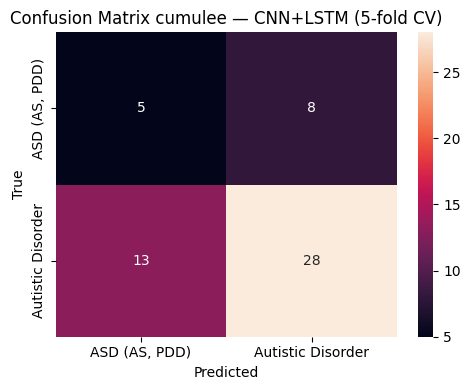


Resultats sauvegardes -> /kaggle/working/cnnlstm_saliency_cv5_summary.csv


In [13]:
metric_cols = [c for c in cv_df.columns if c != 'n_participants_test']
summary = pd.DataFrame({
    'mean': cv_df[metric_cols].mean(),
    'std':  cv_df[metric_cols].std(ddof=1),
})
summary['mean ± std'] = [
    (f"{m:.2f} ± {s:.2f}" if c in ('precision', 'recall', 'f1', 'accuracy') else f"{m:.4f} ± {s:.4f}")
    for c, m, s in zip(summary.index, summary['mean'], summary['std'])
]

print(f"CNN + LSTM multi-tache (saliency maps, Partie B) — CV {N_FOLDS} folds, seed={SEED}")
print("\n=== Niveau PARTICIPANT (precision / recall / F1 / accuracy en %) ===")
for k in ['precision', 'recall', 'f1', 'accuracy', 'auc']:
    print(f"  {k:<10}: {summary.loc[k, 'mean ± std']}")

print("\n=== Niveau IMAGE (par chunk) — regression (tete de regression) ===")
for k in ['MAE_image', 'MSE_image', 'RMSE_image', 'R2_image']:
    print(f"  {k.split('_')[0]:<5}: {summary.loc[k, 'mean ± std']}")

print("\n=== Niveau PARTICIPANT — regression (tete de regression) ===")
for k in ['MAE_participant', 'MSE_participant', 'RMSE_participant', 'R2_participant']:
    print(f"  {k.split('_')[0]:<5}: {summary.loc[k, 'mean ± std']}")

# Matrice de confusion cumulee sur les 5 folds (chaque participant est teste exactement 1 fois)
plt.figure(figsize=(5, 4))
sns.heatmap(cm_total, annot=True, fmt="d", xticklabels=le.classes_, yticklabels=le.classes_)
plt.xlabel("Predicted"); plt.ylabel("True")
plt.title(f"Confusion Matrix cumulee — CNN+LSTM ({N_FOLDS}-fold CV)")
plt.tight_layout(); plt.show()

summary.to_csv(os.path.join(CKPT_DIR, 'cnnlstm_saliency_cv5_summary.csv'))
cv_df.to_csv(os.path.join(CKPT_DIR, 'cnnlstm_saliency_cv5_per_fold.csv'))
print(f"\nResultats sauvegardes -> {CKPT_DIR}/cnnlstm_saliency_cv5_summary.csv")

### 12. Graphiques : scatter, courbe ROC (prédictions out-of-fold) et courbes de loss

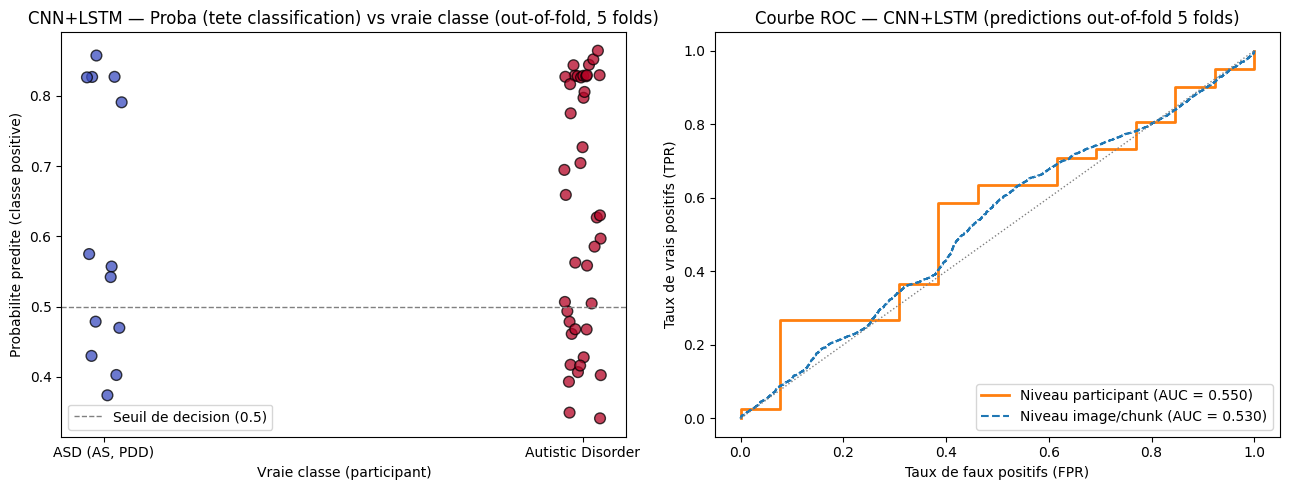

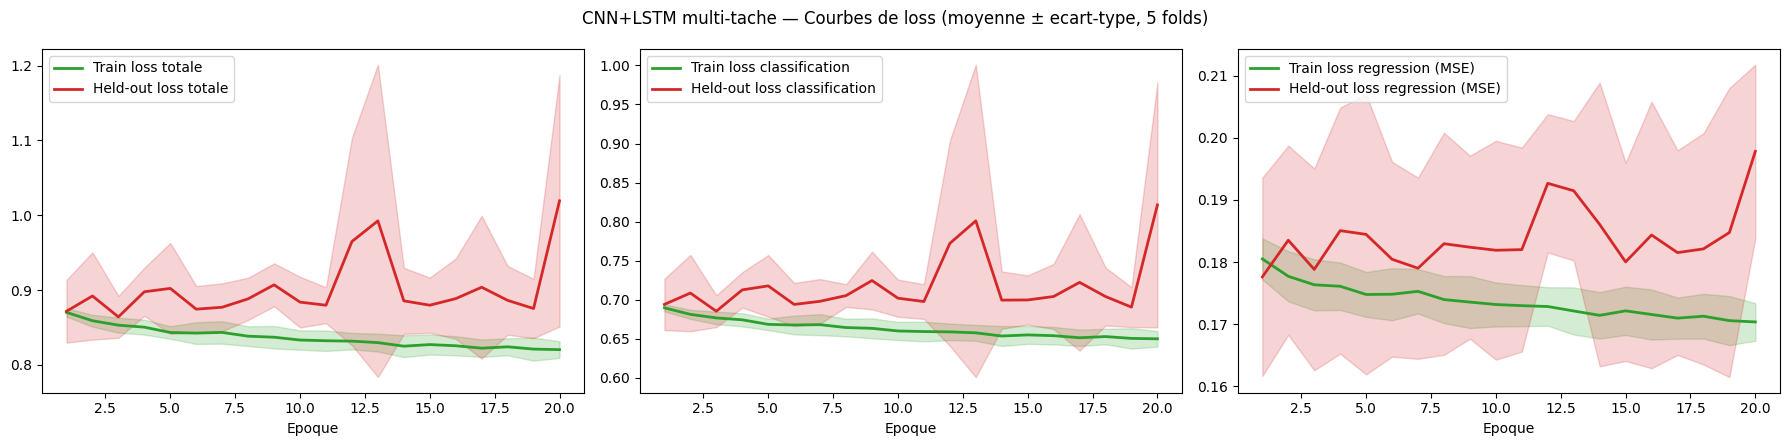

In [ ]:
from sklearn.metrics import roc_curve, auc

y_true_arr = np.array(y_true_cnn_sal)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

ax = axes[0]
jitter = (np.random.rand(len(y_true_arr)) - 0.5) * 0.08
if N_CLASSES == 2:
    ax.scatter(y_true_arr + jitter, y_prob_cnn_sal_p[:, 1], c=y_true_arr, cmap='coolwarm', edgecolor='k', alpha=0.75, s=60)
    ax.axhline(0.5, color='gray', linestyle='--', lw=1, label='Seuil de decision (0.5)')
    ax.set_ylabel("Probabilite predite (classe positive)"); ax.legend()
else:
    ax.scatter(y_true_arr + jitter, y_prob_cnn_sal_p[np.arange(len(y_true_arr)), y_true_arr], c=y_true_arr, cmap='tab10', edgecolor='k', alpha=0.75, s=60)
    ax.set_ylabel("Probabilite predite (pour la vraie classe)")
ax.set_xticks(sorted(set(y_true_arr))); ax.set_xticklabels(le.classes_)
ax.set_xlabel("Vraie classe (participant)")
ax.set_title("CNN+LSTM — Proba (tete classification) vs vraie classe (out-of-fold, 5 folds)")

ax = axes[1]
if N_CLASSES == 2:
    fpr_p, tpr_p, _ = roc_curve(y_true_arr, y_prob_cnn_sal_p[:, 1])
    fpr_i, tpr_i, _ = roc_curve(y_true_img, y_prob_img)
    ax.plot(fpr_p, tpr_p, color='tab:orange', lw=2, label=f"Niveau participant (AUC = {auc(fpr_p, tpr_p):.3f})")
    ax.plot(fpr_i, tpr_i, color='tab:blue', lw=1.5, linestyle='--', label=f"Niveau image/chunk (AUC = {auc(fpr_i, tpr_i):.3f})")
    ax.plot([0, 1], [0, 1], color='gray', lw=1, linestyle=':')
    ax.set_xlabel("Taux de faux positifs (FPR)"); ax.set_ylabel("Taux de vrais positifs (TPR)")
    ax.legend(loc="lower right")
ax.set_title("Courbe ROC — CNN+LSTM (predictions out-of-fold 5 folds)")
plt.tight_layout(); plt.show()

def curve(ax, key, title):
    ep = np.arange(1, EPOCHS + 1)
    for pre, col, lab in [('train', 'tab:green', 'Train'), ('val', 'tab:red', 'Held-out')]:
        arr = np.array([h[f'{pre}_{key}'] for h in histories])
        m, sd = arr.mean(0), arr.std(0, ddof=1)
        ax.plot(ep, m, color=col, lw=2, label=f"{lab} loss {title}")
        ax.fill_between(ep, m - sd, m + sd, color=col, alpha=0.2)
    ax.set_xlabel("Epoque"); ax.legend()

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
curve(axes[0], 'total', 'totale')
curve(axes[1], 'cls',   'classification')
curve(axes[2], 'reg',   'regression (MSE)')
fig.suptitle("CNN+LSTM multi-tache — Courbes de loss (moyenne ± ecart-type, 5 folds)")
plt.tight_layout(); plt.show()